# 05 - Competição LNDb: radiomics em esferas de 4 e 2 mm

## Objetivo e estrutura

Este notebook produz as previsões para a competição (`predictions.csv`) e é um complemento aos notebooks 02 a 04. Os candidatos de teste do LNDb trazem apenas as coordenadas do centro do achado, sem contornos dos radiologistas, pelo que a região de interesse é uma esfera fixa centrada em cada candidato, e não o contorno usado no notebook 04. Combinam-se as características radiómicas de duas esferas, com 4 e 2 mm de raio, e um ExtraTrees de regressão estima a classificação de malignidade; as previsões contínuas são convertidas em classes de 1 a 5 por pontos de corte calibrados.

Os rótulos e as associações de leitores vêm do notebook 01. No LNDb de treino entram apenas achados classificados como nódulo e com todas as classificações de malignidade válidas (1 a 5). O notebook segue esta ordem: configuração, escolha do raio das esferas, extração das características, divisão por paciente, experiência com hiperparâmetros, validação e, por fim, inferência e exportação para a competição.

In [10]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "src/lung_project").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from project/ or project/notebooks/")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import hashlib
import joblib
import json
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lung_project.ct import CropRules
from lung_project.dataset import (
    LNDB_TEST_SHA256,
    load_test_nodules,
    eligible_feature_cohort,
    saved_holdout_split,
)
from lung_project.evaluation import apply_thresholds, validate_training_table
from lung_project.experiments import (
    plot_sphere_crops,
    save_holdout_run,
    snapshot_inputs,
    write_json,
    new_run_path,
    run_hyperparameter_sweep,
    best_hyperparameters,
)
from lung_project.features import prepare_sphere_features, crop_radiomics_extractor, combine_radius_features
from lung_project.modeling import evaluate_sphere_holdout, align_test_features
from lung_project.paths import LNDB_TEST_NODULES, SPHERE_HOLDOUT_SPLIT_PATH, require_file
from lung_project.prepared import (
    enforce_lidc_geometry_policy,
    feature_table_path,
    radiomics_columns,
    radius_key,
    read_radius_features,
)
from lung_project.progress import notebook_progress
from lung_project.scan_pipeline import rebuild_sphere_crops, rules_id
from sklearn.metrics import ConfusionMatrixDisplay

# Hide only the redundant symmetric-GLCM message; retain other warnings.
logging.getLogger("radiomics.glcm").addFilter(
    lambda record: not record.getMessage().startswith(
        "GLCM is symmetrical, therefore Sum Average = 2 * Joint Average"
    )
)

## Configuração

As definições editáveis estão no início da célula seguinte:

- `ROI_RADII_MM = (4, 2)`: raios das esferas cujas características são combinadas (ver secção seguinte).
- `CONTEXT_MARGIN_MM = 0.0`: os filtros de imagem usam apenas a caixa delimitadora justa de cada esfera.
- `REGENERATE_CROPS = False`: reutiliza os recortes guardados; `True` recria-os a partir dos exames CT originais. Em ambos os casos aplica-se a política geométrica do LIDC (ver secção dos recortes).
- `FIRST_SCAN_ONLY = False`: com `True`, faz um ensaio rápido com o primeiro exame de cada conjunto de dados, sem alterar as exportações completas.
- `EXPORT_SUBMISSION = True`: escreve `predictions.csv` no fim do notebook.
- `TRAINING_TARGET = "mean_rating"`: o regressor aprende a média não arredondada das classificações dos leitores (por exemplo, 2 e 3 dão 2,5). Os pontos de corte e as métricas usam o rótulo arredondado, que é o alvo da competição.
- `THRESHOLD_OBJECTIVE = "leaderboard"`: os pontos de corte maximizam exatidão equilibrada + F1 macro + QWK - MAE. A competição ordena as equipas pela média das posições nestas quatro métricas, pelo que esta soma é uma aproximação.
- `LNDB_WEIGHT = 6.0`: peso das amostras do LNDb, o conjunto da competição; as do LIDC têm peso 1.

A configuração base é um ExtraTrees com 200 árvores, profundidade máxima 20, folhas com pelo menos 2 nódulos e `max_features = 1.0`. Com este valor, cada divisão considera todas as características, e a aleatoriedade do ExtraTrees vem apenas dos pontos de corte sorteados em cada divisão. `HYPERPARAMETER_VALUES` define as alternativas comparadas na experiência com hiperparâmetros.

In [11]:
ROI_RADII_MM = (4, 2)
CONTEXT_MARGIN_MM = 0.0  # Filter context around each sphere; the sphere mask is unchanged.
REGENERATE_CROPS = False  # Rebuild from the original CT datasets with the LIDC geometry policy.
FIRST_SCAN_ONLY = False
EXPORT_SUBMISSION = True
TRAINING_TARGET = "mean_rating"  # "mean_rating": unrounded reader mean; "label": rounded label.
THRESHOLD_OBJECTIVE = "leaderboard"  # "leaderboard": balanced accuracy + macro F1 + QWK - MAE; "qwk": QWK only.
CALIBRATE_THRESHOLDS_LNDB_ONLY = False  # False pools LIDC and LNDb threshold patients.
LNDB_WEIGHT = 6.0  # Dataset multiplier applied after within-dataset SMOTE.
CORRELATION_THRESHOLD = 0.85
N_ESTIMATORS = 200
N_JOBS = -1
N_BOOTSTRAP = 2000  # Patient resamples for confidence intervals.
MODEL_NAMES = ("ExtraTrees",)
MODEL_SETTINGS = {
    "min_samples_leaf": 2,
    "min_samples_split": 2,
    "max_features": 1.0,
    "max_depth": 20,
}
THRESHOLD_STRATEGIES = ("calibrated",)
# Alternatives compared one at a time on selection patients; the best value of each
# replaces the FIT_SETTINGS value in SELECTED_FIT_SETTINGS.
HYPERPARAMETER_VALUES = {
    "n_estimators": (100, 500),
    "max_depth": (10, None),
    "min_samples_leaf": (1, 5),
}

if THRESHOLD_OBJECTIVE not in ("leaderboard", "qwk"):
    raise ValueError("THRESHOLD_OBJECTIVE must be 'leaderboard' or 'qwk'")
if TRAINING_TARGET not in ("mean_rating", "label"):
    raise ValueError("TRAINING_TARGET must be 'mean_rating' or 'label'")
if not ROI_RADII_MM or len({radius_key(radius) for radius in ROI_RADII_MM}) != len(ROI_RADII_MM):
    raise ValueError("ROI_RADII_MM must contain distinct positive finite radii")

RADIOMICS_PATH = require_file(PROJECT_ROOT / "config/radiomics.yaml")
CROP_CONFIG_PATH = require_file(PROJECT_ROOT / "config/scan_processing.json")
radiomics_bytes = RADIOMICS_PATH.read_bytes()
radiomics_sha256 = hashlib.sha256(radiomics_bytes).hexdigest()
radii_name = "_".join(radius_key(radius) for radius in ROI_RADII_MM)
RUN_DIR = new_run_path(
    PROJECT_ROOT,
    f"radiomics_{radii_name}mm_context{CONTEXT_MARGIN_MM:g}_holdout_corr{CORRELATION_THRESHOLD * 100:03.0f}"
    f"_standardscaler_dataset_smote_{radiomics_sha256[:12]}",
    lndb_weight=LNDB_WEIGHT,
    tags=[
        "lndbthresholds" if CALIBRATE_THRESHOLDS_LNDB_ONLY else "",
        "leaderboardthresholds" if THRESHOLD_OBJECTIVE == "leaderboard" else "",
        "meantarget" if TRAINING_TARGET == "mean_rating" else "",
    ],
)
RUN_NAME = RUN_DIR.name
SPLIT_PATH = PROJECT_ROOT / "outputs/reports" / SPHERE_HOLDOUT_SPLIT_PATH.name
SPLIT_CONFIG_PATH = require_file(PROJECT_ROOT / "config/sphere_holdout.json")
SPLIT_SETTINGS = json.loads(SPLIT_CONFIG_PATH.read_text())
FIT_SETTINGS = {
    **MODEL_SETTINGS,
    "n_estimators": N_ESTIMATORS,
    "n_jobs": N_JOBS,
    "lndb_weight": LNDB_WEIGHT,
    "use_smote": True,
    "correlation_threshold": CORRELATION_THRESHOLD,
    "standardize": True,
    "training_target": TRAINING_TARGET,
}
EVALUATION_SETTINGS = {
    "selection_dataset": "lndb",
    "model_names": MODEL_NAMES,
    "lndb_only": CALIBRATE_THRESHOLDS_LNDB_ONLY,
    "threshold_strategies": THRESHOLD_STRATEGIES,
    "threshold_objective": THRESHOLD_OBJECTIVE,
}

## Escolha do raio das esferas

Uma esfera centrada no candidato inclui, além do nódulo, o pulmão à sua volta. Uma esfera grande cobre melhor os nódulos maiores, mas, nos nódulos pequenos, que são a maioria, dilui o sinal com parênquima pulmonar. Em experiências anteriores testaram-se esferas de 2, 4, 5, 6, 10 e 15 mm de raio, cada uma isoladamente. O desempenho desceu à medida que o raio aumentou, e os raios de 2 e 4 mm foram os mais promissores, com resultados muito próximos.

Como nenhum dos dois foi claramente melhor, combinam-se ambos: a esfera de 2 mm descreve o interior do nódulo e a de 4 mm acrescenta a margem e o tecido envolvente. As características de cada raio recebem os sufixos `__r4` e `__r2` e são alinhadas pelo identificador do candidato.

## Recortes esféricos

Com `REGENERATE_CROPS = True`, os recortes de 23 x 23 x 23 voxels (espaçamento de 0,4 mm, limitados a [-1000, 400] HU) são recriados a partir dos exames CT originais, como no notebook 02; com `False`, reutilizam-se os guardados. Em ambos os casos aplica-se a política geométrica do LIDC (`config/lidc_geometry_policy.json`), a mesma do notebook 02: excluem-se as séries 0085, 0123, 0146 e 0672, com erros de geometria na origem (5 candidatos, 2 deles da 0085), e reparam-se as séries 0267 e 0572. A escolha destas séries foi informada pelos alvos, o que pode afetar a distribuição das classes.


In [12]:
geometry_policy = json.loads((PROJECT_ROOT / "config/lidc_geometry_policy.json").read_text())
if REGENERATE_CROPS:
    crop_settings = json.loads(CROP_CONFIG_PATH.read_text())
    sphere_manifests, crop_report = rebuild_sphere_crops(
        PROJECT_ROOT,
        CropRules.from_json(CROP_CONFIG_PATH),
        save_native=crop_settings["save_native_crop"],
        geometry_policy=geometry_policy,
    )
    display(crop_report)
    plot_sphere_crops(PROJECT_ROOT, sphere_manifests)
# Apply the same policy to saved sphere crops when regeneration is disabled.
lidc_geometry_manifest = enforce_lidc_geometry_policy(
    geometry_policy, CropRules.from_json(CROP_CONFIG_PATH),
    project_root=PROJECT_ROOT, crop_variant="4mm",
)
print("LIDC sphere crop status:", lidc_geometry_manifest.status.value_counts().to_dict())


LIDC sphere crop status: {'saved': 2560, 'excluded_by_review': 125, 'excluded_source_geometry': 5}


## Extração das características

Extraem-se com o PyRadiomics, segundo `config/radiomics.yaml`, as características de intensidade e textura de cada esfera, para os três conjuntos de dados (LIDC, LNDb de treino e LNDb de teste) e os dois raios. As características de forma ficam desativadas, porque a máscara é uma esfera artificial e não a forma da lesão. As tabelas já extraídas com a mesma configuração e os mesmos recortes são reutilizadas; só as que faltam ou estão desatualizadas são extraídas de novo.

In [13]:
feature_tables = prepare_sphere_features(
    PROJECT_ROOT,
    RADIOMICS_PATH,
    CropRules.from_json(CROP_CONFIG_PATH),
    radii=ROI_RADII_MM,
    context_margin_mm=CONTEXT_MARGIN_MM,
    first_scan_only=FIRST_SCAN_ONLY,
    progress=notebook_progress(),
)

/home/pera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:332: DtypeWarning: Columns (116: source_dicom_read_options) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


lidc 4 mm: reused verified features

/home/pera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:332: DtypeWarning: Columns (116: source_dicom_read_options) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


lidc 2 mm: reused verified features

lndb_train 4 mm: reused verified features

lndb_train 2 mm: reused verified features

lndb_test 4 mm: reused verified features

lndb_test 2 mm: reused verified features

A primeira tabela mostra, por conjunto de dados e raio, o número de candidatos, as extrações bem-sucedidas, o número de preditores e quantos têm valores em falta ou não finitos entre as linhas extraídas. Os candidatos não extraídos são os excluídos no notebook 01 (não-nódulos do LNDb, achados removidos na revisão e classificações inválidas), os que têm coordenadas fora do exame e as séries LIDC excluídas pela política geométrica. A segunda tabela conta os preditores por família, iguais em todos os conjuntos de dados.

In [14]:
feature_quality_rows = []
for (subset, radius_mm), table in feature_tables.items():
    columns = radiomics_columns(table)
    extracted = table.loc[table.extraction_status.eq("ok"), columns]
    numeric = extracted.apply(pd.to_numeric, errors="raise").replace([np.inf, -np.inf], np.nan)
    feature_quality_rows.append(
        {
            "subset": subset,
            "radius_mm": radius_mm,
            "candidates": len(table),
            "extracted": len(extracted),
            "not_extracted": len(table) - len(extracted),
            "predictors": len(columns),
            "predictors_with_missing_values": int(numeric.isna().any().sum()),
        }
    )
display(pd.DataFrame(feature_quality_rows))
families = {
    key: pd.Series([name.split("_")[1] for name in radiomics_columns(table)]).value_counts()
    for key, table in feature_tables.items()
}
if any(not counts.equals(next(iter(families.values()))) for counts in families.values()):
    raise ValueError("Feature families differ between subsets or radii")
display(next(iter(families.values())).rename("predictors_per_radius").to_frame())

,subset,radius_mm,candidates,extracted,not_extracted,predictors,predictors_with_missing_values
0,lidc,4,2690,2560,130,744,0
1,lidc,2,2690,2560,130,744,0
2,lndb_train,4,1219,758,461,744,0
3,lndb_train,2,1219,758,461,744,0
4,lndb_test,4,2900,2895,5,744,0
5,lndb_test,2,2900,2895,5,744,0


,predictors_per_radius
glcm,192
firstorder,144
glrlm,128
glszm,128
gldm,112
ngtdm,40


## Dados e divisão por paciente

Leem-se as tabelas registadas e combinam-se os preditores dos dois raios. Verifica-se que todas foram extraídas com a configuração desta execução e que nenhum paciente do LNDb de treino aparece no teste da competição. Os candidatos de treino têm de ter sido extraídos com sucesso nos dois raios.

A divisão holdout é a mesma das execuções anteriores deste notebook (`config/sphere_holdout.json`); é criada uma vez e reutilizada, e todos os nódulos de cada paciente ficam na mesma partição:

| Partição | Utilização | Nunca usada para |
|---|---|---|
| ajuste (`fitting`), ~52% | filtro de correlação, imputação pela mediana, `StandardScaler`, SMOTE e ExtraTrees | qualquer outra decisão |
| limiares (`threshold`), 15% | calibrar os pontos de corte com previsões de um modelo que não viu estes pacientes | ajuste, seleção, resultados |
| seleção (`selection`), ~13% | comparar os hiperparâmetros com os pontos de corte já fixos | ajuste, calibração dos limiares |
| validação (`validation`), 20% | uma única avaliação da configuração escolhida | qualquer decisão |

O SMOTE é aplicado separadamente ao LIDC e ao LNDb, apenas nas linhas de ajuste, depois de ajustados a imputação e o `StandardScaler` nas linhas originais. As partições de limiares, seleção e validação e o teste nunca são reamostrados.

In [15]:
radius_tables = {
    subset: {radius: read_radius_features(subset, radius, crop_variant="4mm") for radius in ROI_RADII_MM}
    for subset in ("lidc", "lndb_train", "lndb_test")
}
expected_signature = {
    "rules_id": rules_id(CropRules.from_json(CROP_CONFIG_PATH)),
    "roi_definition": "fixed_center_sphere",
    "radiomics_config_sha256": radiomics_sha256,
    "context_margin_mm": CONTEXT_MARGIN_MM,
    "context_policy": "bbox_context_clipped_to_saved_crop_mask_unchanged",
}
for subset, representations in radius_tables.items():
    for radius, table in representations.items():
        for column, expected in {**expected_signature, "roi_radius_mm": radius}.items():
            if table[column].isna().any() or not table[column].eq(expected).all():
                raise ValueError(f"{subset} {radius} mm: {column} differs from this run; rerun extraction")
tables = {
    subset: combine_radius_features(representations) for subset, representations in radius_tables.items()
}
lidc, lndb_train, test_features = (tables[name] for name in ("lidc", "lndb_train", "lndb_test"))
if any(set(radiomics_columns(table)) != set(radiomics_columns(lidc)) for table in tables.values()):
    raise ValueError("Training and test radiomics predictor schemas differ")
raw_training = pd.concat([lidc, lndb_train], ignore_index=True, sort=False)
test_candidates = load_test_nodules(require_file(LNDB_TEST_NODULES), expected_sha256=LNDB_TEST_SHA256)
if not set(lndb_train.LNDbID).isdisjoint(test_candidates.LNDbID):
    raise ValueError("LNDb training and competition test patients overlap")
aligned_test = align_test_features(test_candidates, test_features)

eligible_training = eligible_feature_cohort(raw_training)
shared_split, training = saved_holdout_split(raw_training, path=SPLIT_PATH, settings=SPLIT_SETTINGS)
feature_columns = validate_training_table(training)
SEED = shared_split["settings"]["seed"]
split_rows = []
for role in ("fitting", "threshold", "selection", "validation"):
    selected = training.loc[training.candidate_id.isin(shared_split["partitions"][role]["candidate_ids"])]
    for dataset, rows in selected.groupby("dataset", sort=True):
        split_rows.append(
            {
                "partition": role,
                "dataset": dataset,
                "patients": rows.patient_id.nunique(),
                "nodules": len(rows),
                **{
                    f"rating_{rating}": int(rows.malignancy_target.eq(rating).sum()) for rating in range(1, 6)
                },
            }
        )
split_counts = pd.DataFrame(split_rows)
display(split_counts)
print(
    f"{len(feature_columns)} predictors ({len(ROI_RADII_MM)} radii); "
    f"{len(eligible_training) - len(training)} eligible candidates outside the reference cohort"
)

/home/pera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:332: DtypeWarning: Columns (116: source_dicom_read_options) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(
/home/pera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:332: DtypeWarning: Columns (116: source_dicom_read_options) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


,partition,dataset,patients,nodules,rating_1,rating_2,rating_3,rating_4,rating_5
0,fitting,lidc,438,1331,150,313,612,192,64
1,fitting,lndb,110,394,111,132,106,36,9
2,threshold,lidc,126,383,43,89,177,56,18
3,threshold,lndb,31,114,32,38,30,11,3
4,selection,lidc,110,333,38,78,153,48,16
5,selection,lndb,27,98,28,33,26,9,2
6,validation,lidc,169,512,58,120,235,74,25
7,validation,lndb,42,152,42,51,41,14,4


1488 predictors (2 radii); 1 eligible candidates outside the reference cohort


## Registo dos dados de entrada da experiência

Antes do treino, guardam-se na pasta da experiência cópias exatas do YAML, das definições efetivas do extrator, das regras dos recortes, da configuração e do manifesto da divisão e das tabelas de características, para que a execução possa ser reproduzida mesmo que as exportações mudem.

In [16]:
extractor = crop_radiomics_extractor(RADIOMICS_PATH)
if RADIOMICS_PATH.read_bytes() != radiomics_bytes:
    raise RuntimeError("Radiomics configuration changed during setup; restart this run")
effective_radiomics = {
    "setting": extractor.settings,
    "imageType": extractor.enabledImagetypes,
    "featureClass": extractor.enabledFeatures,
}
input_paths = (
    [SPLIT_CONFIG_PATH]
    + [feature_table_path(name, radius) for name in tables for radius in ROI_RADII_MM]
    + [PROJECT_ROOT / "outputs/prepared" / f"{name}_crops_4mm.csv" for name in tables]
    + [
        PROJECT_ROOT / "outputs/prepared/stages.json",
        SPLIT_PATH,
        RADIOMICS_PATH,
        CROP_CONFIG_PATH,
        LNDB_TEST_NODULES,
    ]
)
copies = {
    "sphere_holdout.json": SPLIT_CONFIG_PATH,
    "radiomics.yaml": RADIOMICS_PATH,
    "scan_processing.json": CROP_CONFIG_PATH,
    "patient_split.json": SPLIT_PATH,
}
for subset in tables:
    for radius in ROI_RADII_MM:
        path = feature_table_path(subset, radius)
        copies[path.name] = path
snapshot_tables = {f"{subset}_features_combined.csv": table for subset, table in tables.items()}
snapshot_tables["split_counts.csv"] = split_counts
input_sha256 = snapshot_inputs(
    PROJECT_ROOT,
    RUN_DIR,
    input_paths=input_paths,
    copies=copies,
    tables=snapshot_tables,
)
write_json(RUN_DIR / "radiomics_effective.json", effective_radiomics)

## Experiência: hiperparâmetros do ExtraTrees

Como no notebook 04, comparam-se alterações a `n_estimators`, `max_depth` e `min_samples_leaf`, um parâmetro de cada vez, mantendo os restantes valores, o SMOTE, os pesos e a divisão por paciente. A configuração base é incluída como referência. Cada configuração é ajustada nos pacientes de ajuste, os pontos de corte são calibrados nos pacientes de limiares e a QWK é medida nos pacientes de seleção; os pacientes de validação não são previstos. Para cada parâmetro, escolhe-se o valor com maior QWK nos pacientes de seleção do LNDb. A QWK agregada (LIDC e LNDb) é apresentada apenas como referência. A seleção do LNDb tem 27 pacientes, pelo que as diferenças devem ser interpretadas com os respetivos intervalos de confiança. Os valores escolhidos substituem os da base em `SELECTED_FIT_SETTINGS`.

Como cada parâmetro varia isoladamente, a combinação dos valores escolhidos não é avaliada nesta experiência; aparece na secção seguinte. Os resultados de cada configuração ficam em `hyperparameter_sweep/`, na pasta da experiência.

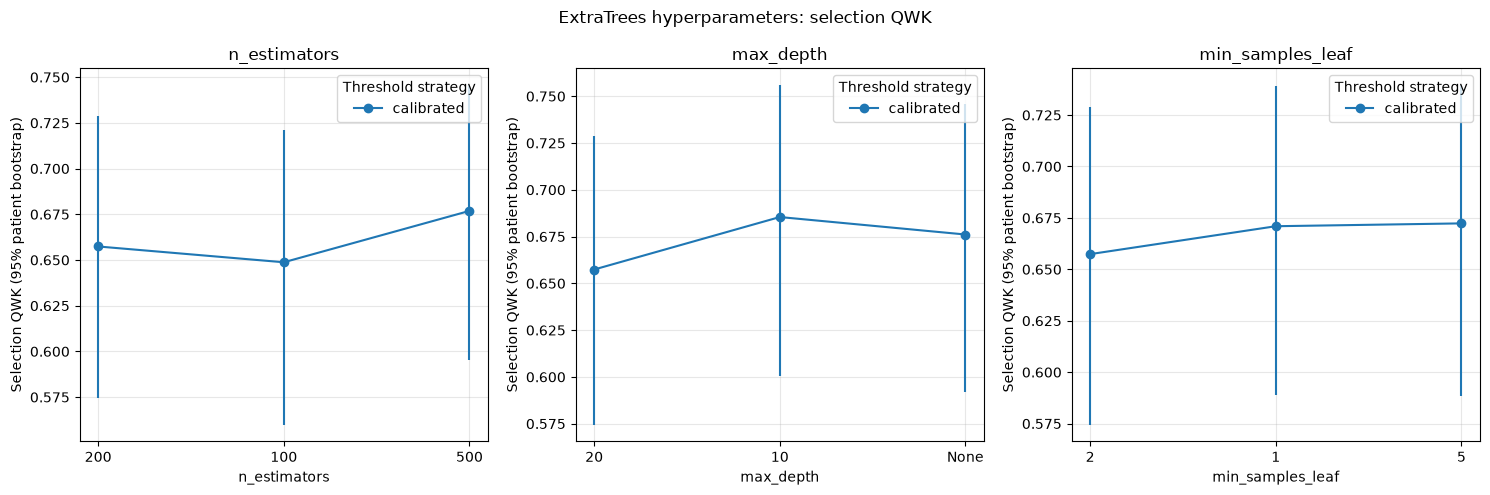

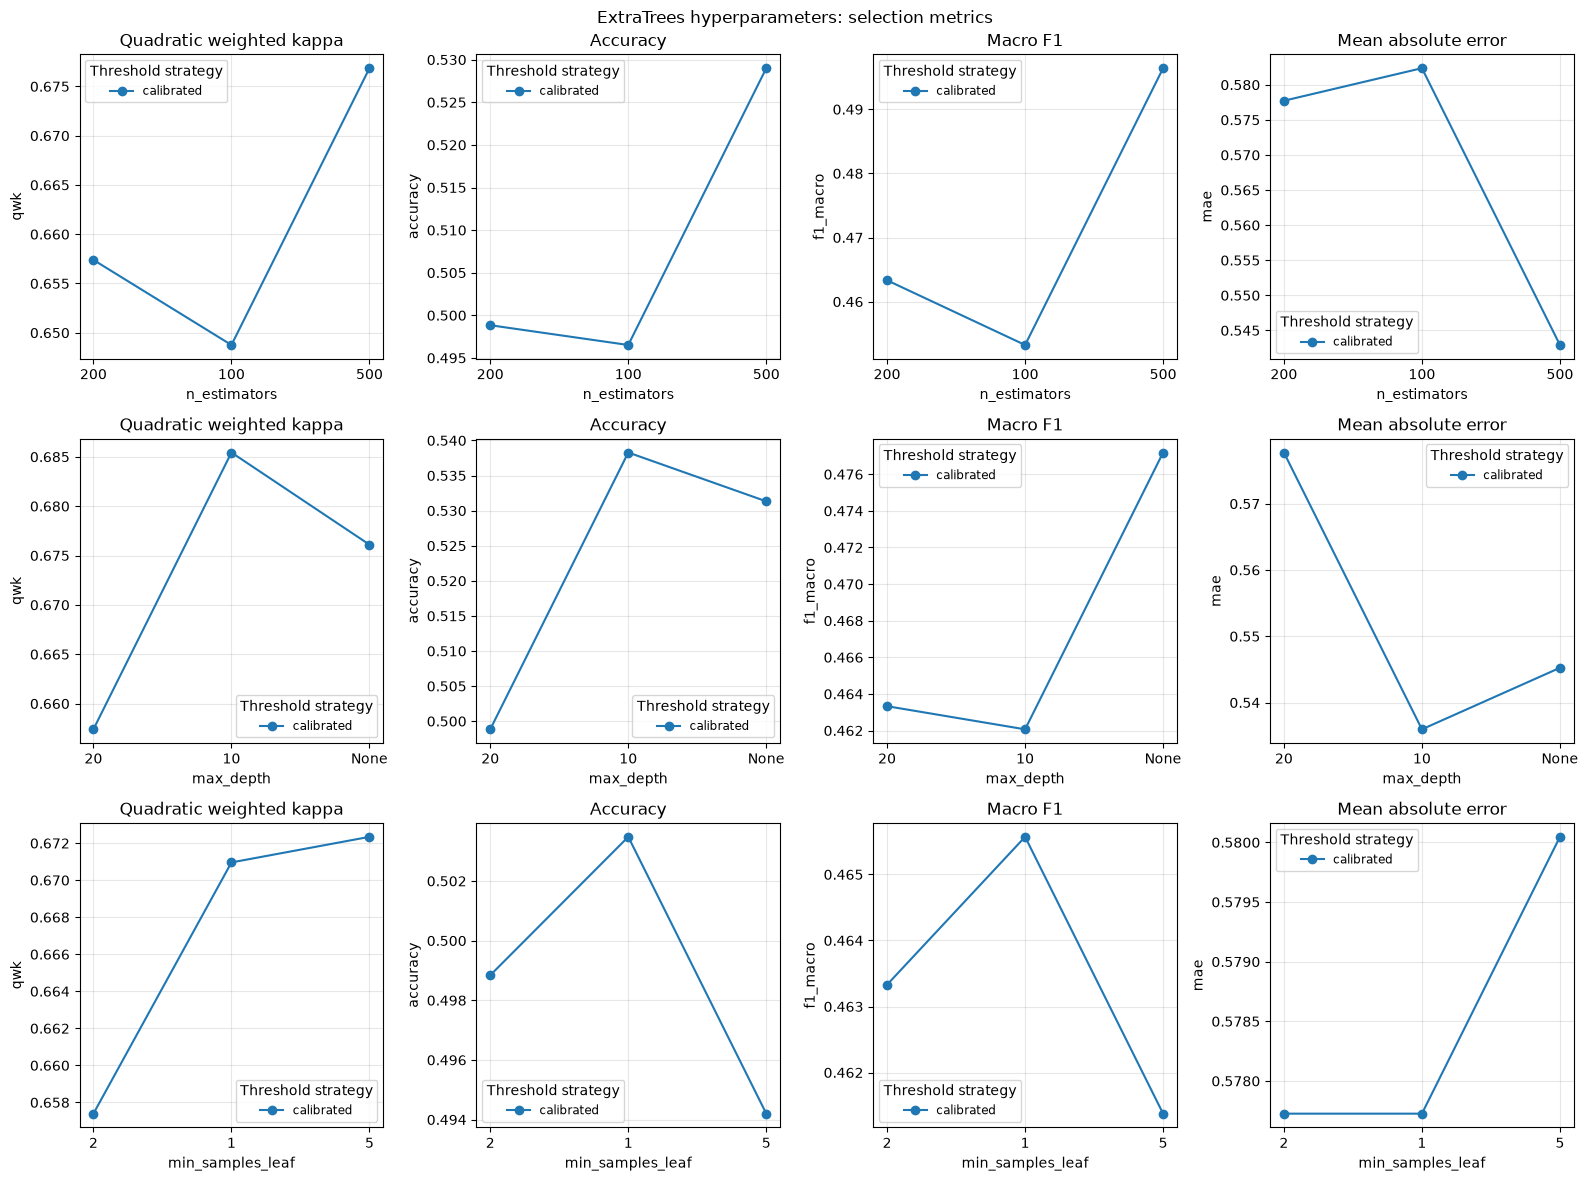

qwk         qwk_lower qwk_upper  \
dataset                         lndb  pooled    pooled    pooled   
hyperparameter   value_label                                       
max_depth        10           0.5967  0.6854    0.6006    0.7558   
                 20           0.5277  0.6574    0.5746    0.7289   
                 None         0.5491  0.6761    0.5918    0.7461   
min_samples_leaf 1            0.5614  0.6710    0.5889    0.7391   
                 2            0.5277  0.6574    0.5746    0.7289   
                 5            0.5676  0.6723    0.5884    0.7395   
n_estimators     100          0.5192  0.6488    0.5600    0.7209   
                 200          0.5277  0.6574    0.5746    0.7289   
                 500          0.5942  0.6769    0.5951    0.7455   

                             balanced_accuracy         f1_macro          \
dataset                                   lndb  pooled     lndb  pooled   
hyperparameter   value_label                                              
max_depth        10                     0.3455  0.4859   0.3398  0.4621   
                 20                     0.3208  0.4723   0.3172  0.4633   
                 None                   0.3518  0.4906   0.3496  0.4772   
min_samples_leaf 1                      0.3320  0.4933   0.3245  0.4656   
                 2                      0.3208  0.4723   0.3172  0.4633   
                 5                      0.3290  0.4851   0.3266  0.4614   
n_estimators     100                    0.3213  0.4608   0.3214  0.4532   
                 200                    0.3208  0.4723   0.3172  0.4633   
                 500                    0.3799  0.5038   0.3862  0.4964   

                                 mae          
dataset                         lndb  pooled  
hyperparameter   value_label                  
max_depth        10           0.6327  0.5360  
                 20           0.6837  0.5777  
                 None         0.6633  0.5452  
min_samples_leaf 1            0.6837  0.5777  
                 2            0.6837  0.5777  
                 5            0.6633  0.5800  
n_estimators     100          0.6837  0.5824  
                 200          0.6837  0.5777  
                 500          0.5816  0.5429

Selected by LNDb selection QWK: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 500}


In [17]:
hyperparameter_selection_metrics = run_hyperparameter_sweep(
    training,
    feature_columns,
    shared_split,
    RUN_DIR,
    parameter_values=HYPERPARAMETER_VALUES,
    fit_settings=FIT_SETTINGS,
    evaluation_settings=EVALUATION_SETTINGS,
    n_bootstrap=N_BOOTSTRAP,
    evaluate=evaluate_sphere_holdout,
    model_label="ExtraTrees",
)
display(
    hyperparameter_selection_metrics.loc[
        hyperparameter_selection_metrics.dataset.isin(["pooled", "lndb"]),
        ["hyperparameter", "value_label", "dataset", "qwk", "qwk_lower", "qwk_upper", "balanced_accuracy", "f1_macro", "mae"],
    ]
    .pivot(index=["hyperparameter", "value_label"], columns="dataset")
    .dropna(axis=1, how="all")
    .round(4)
)
SELECTED_HYPERPARAMETERS = best_hyperparameters(hyperparameter_selection_metrics, dataset="lndb")
SELECTED_FIT_SETTINGS = {**FIT_SETTINGS, **SELECTED_HYPERPARAMETERS}
print("Selected by LNDb selection QWK:", SELECTED_HYPERPARAMETERS)

### Leitura da experiência com hiperparâmetros

Na seleção do LNDb, a configuração base obteve QWK **0,5277**. As alterações com maior QWK foram `max_depth = 10` (**0,5967**, contra **0,5491** sem limite), `n_estimators = 500` (**0,5942**, contra **0,5192** com 100) e `min_samples_leaf = 5` (**0,5676**, contra **0,5614** com 1). Escolhem-se, por isso, 500 árvores, profundidade máxima 10 e folhas com pelo menos 5 nódulos. Na seleção agregada, a ordem é a mesma em `max_depth` e `n_estimators`, e as diferenças são menores (de **0,6488** a **0,6854**), face a intervalos de 95% com cerca de 0,15 de largura.

Estas escolhas devem ser lidas como ajustes finos, não como melhorias demonstradas. A seleção do LNDb tem apenas 27 pacientes (98 nódulos), e na seleção agregada todos os intervalos de 95% se sobrepõem largamente. Cada configuração foi também avaliada com uma única semente, pelo que parte das diferenças pode resultar das amostras sorteadas pelo SMOTE e pelas árvores.

Com a combinação escolhida, a QWK de seleção foi **0,6903** no conjunto agregado e **0,5984** no LNDb, acima da configuração base, mas praticamente igual à melhor alteração isolada no LNDb (**0,5967**).

## Modelo final: seleção, validação e reajuste

Com `SELECTED_FIT_SETTINGS`, ajusta-se o ExtraTrees nos pacientes de ajuste, calibram-se os pontos de corte nos pacientes de limiares e preveem-se uma única vez os pacientes de validação. Depois, reajusta-se o modelo com todos os pacientes elegíveis exceto os de limiares e calibram-se de novo os pontos de corte nesses pacientes, com as previsões do modelo final. A validação estima, portanto, este procedimento; o modelo submetido não tem uma avaliação independente própria.

In [18]:
holdout_result = evaluate_sphere_holdout(
    training,
    feature_columns,
    shared_split,
    final_cohort=eligible_training,
    n_bootstrap=N_BOOTSTRAP,
    **SELECTED_FIT_SETTINGS,
    **EVALUATION_SETTINGS,
)
validated_artifact = holdout_result["validated_model"]
selected_artifact = holdout_result["final_model"]
selected_thresholds = holdout_result["final_thresholds"]
metric_view = ["dataset", "nodules", "patients", "qwk", "balanced_accuracy", "f1_macro", "mae", "accuracy"]
print("Selection patients (combined configuration):")
display(holdout_result["selection_metrics"][metric_view].round(4))
print(
    f"Predictors after the correlation filter: validated model {len(validated_artifact.features)}, "
    f"final model {len(selected_artifact.features)}, of {len(feature_columns)}"
)

Holdout: fitting ExtraTrees on 548 fitting patients
Holdout: ExtraTrees / calibrated predicts 211 validation patients once
Final refit on 897 patients outside the threshold partition
Selection patients (combined configuration):


,dataset,nodules,patients,qwk,balanced_accuracy,f1_macro,mae,accuracy
0,pooled,431,137,0.6903,0.5124,0.4647,0.5406,0.5383
1,lidc,333,110,0.6920,0.5338,0.4818,0.5135,0.5495
2,lndb,98,27,0.5984,0.3614,0.3512,0.6327,0.5000


Predictors after the correlation filter: validated model 351, final model 350, of 1488


## Avaliação na validação

Os intervalos de 95% resultam de 2 000 reamostragens de pacientes completos de validação dentro de cada conjunto de dados, e descrevem a variabilidade deste conjunto de validação, não a do treino. A comparação dos pontos de corte mostra os valores calibrados para o modelo validado e para o modelo final, e as classes que cada um produz nos pacientes de limiares. As matrizes de confusão estão normalizadas por linha (fração de cada classe verdadeira); a do LNDb é a mais relevante para a competição.

,dataset,nodules,patients,qwk,balanced_accuracy,f1_macro,mae,accuracy
0,pooled,664,211,0.6717,0.4814,0.4406,0.5422,0.5301
1,lidc,512,169,0.6806,0.4928,0.4449,0.5137,0.5469
2,lndb,152,42,0.5969,0.4798,0.4234,0.6382,0.4737


estimate                   lower                   upper  \
dataset               lidc    lndb  pooled    lidc    lndb  pooled    lidc   
metric                                                                       
balanced_accuracy   0.4928  0.4798  0.4814  0.4346  0.3178  0.4295  0.5542   
f1_macro            0.4449  0.4234  0.4406  0.3930  0.2967  0.3948  0.4921   
mae                 0.5137  0.6382  0.5422  0.4523  0.5148  0.4839  0.5802   
qwk                 0.6806  0.5969  0.6717  0.6040  0.4361  0.6088  0.7404   

                                   
dataset              lndb  pooled  
metric                             
balanced_accuracy  0.5696  0.5360  
f1_macro           0.4963  0.4810  
mae                0.7770  0.6010  
qwk                0.7090  0.7256

,cut_point,validated,final,difference
0,1|2,2.0672,1.9000,-0.1672
1,2|3,2.3720,2.4418,0.0698
2,3|4,3.1565,3.4460,0.2895
3,4|5,3.7340,3.9396,0.2055


,rating,observed,validated_predicted,final_predicted
0,1,75,75,70
1,2,127,78,87
2,3,207,256,266
3,4,67,32,33
4,5,21,56,41


,patient_id,dataset,malignancy_target,continuous_prediction,prediction,absolute_error
2470,LIDC-IDRI-0629,lidc,2.0,4.029,5,3.0
2574,LNDb-0004,lndb,2.0,4.257,5,3.0
2787,LNDb-0080,lndb,2.0,3.797,5,3.0
2415,LIDC-IDRI-1009,lidc,2.0,4.115,5,3.0
1781,LIDC-IDRI-0993,lidc,1.0,3.512,4,3.0
1365,LIDC-IDRI-0571,lidc,1.0,3.240,4,3.0
287,LIDC-IDRI-0892,lidc,4.0,1.416,1,3.0
3003,LNDb-0182,lndb,3.0,2.005,1,2.0
1014,LIDC-IDRI-0450,lidc,5.0,3.114,3,2.0
2250,LIDC-IDRI-0002,lidc,5.0,2.880,3,2.0


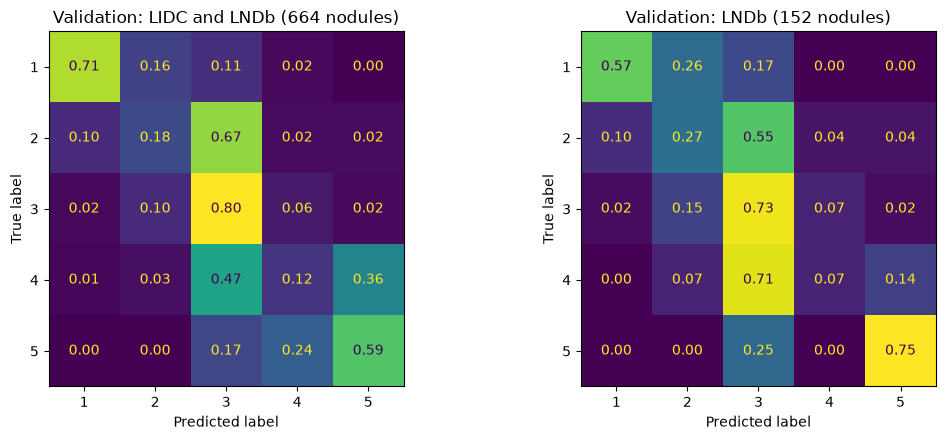

In [19]:
validation_metrics = holdout_result["validation_metrics"]
display(validation_metrics[metric_view].round(4))
display(
    holdout_result["validation_intervals"]
    .pivot(index="metric", columns="dataset", values=["estimate", "lower", "upper"])
    .round(4)
)
display(holdout_result["threshold_check"].round(4))
display(holdout_result["threshold_rating_counts"])

validation_errors = holdout_result["validation_predictions"].copy()
validation_errors["absolute_error"] = (validation_errors.malignancy_target - validation_errors.prediction).abs()
display(
    validation_errors.sort_values("absolute_error", ascending=False)
    .head(10)[["patient_id", "dataset", "malignancy_target", "continuous_prediction", "prediction", "absolute_error"]]
    .round(3)
)
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, (title, rows) in zip(
    axes,
    [("Validation: LIDC and LNDb", validation_errors), ("Validation: LNDb", validation_errors.query("dataset == 'lndb'"))],
):
    ConfusionMatrixDisplay.from_predictions(
        rows.malignancy_target.astype(int),
        rows.prediction,
        labels=[1, 2, 3, 4, 5],
        normalize="true",
        values_format=".2f",
        colorbar=False,
        ax=axis,
    )
    axis.set_title(f"{title} ({len(rows)} nodules)")
plt.tight_layout()
plt.show()

### Leitura dos resultados de validação

Na validação, a QWK foi **0,6717** no conjunto agregado, **0,6806** no LIDC e **0,5969** no LNDb, com intervalos de 95% **[0,6088; 0,7256]**, **[0,6040; 0,7404]** e **[0,4361; 0,7090]**. Com 42 pacientes, o intervalo do LNDb é largo. A exatidão equilibrada e o F1 macro do LNDb (**0,4798** e **0,4234**) ficam próximos dos do LIDC (**0,4928** e **0,4449**), mas o MAE do LNDb é maior (**0,6382**, contra **0,5137**).

Os pontos de corte do modelo final diferem dos do modelo validado: o corte 1|2 desce 0,17, e os cortes 3|4 e 4|5 sobem 0,29 e 0,21. Nos 497 nódulos dos pacientes de limiares (observados: 75, 127, 207, 67 e 21 nas classes 1 a 5), o modelo final prevê 70, 87, **266**, **33** e 41. A classe 3 recebe nódulos em excesso, sobretudo das classes 2 e 4, e a classe 4 recebe cerca de metade dos nódulos observados. A classe 5 é prevista mais vezes do que é observada.

Os maiores erros (3 classes) são sobretudo nódulos classificados como 1 ou 2 pelos leitores e previstos como 4 ou 5, dois deles do LNDb; só um nódulo de classe 4 é previsto como 1.

## Previsões para a competição

O modelo final prevê os 2 900 candidatos de teste, pela ordem original. Cinco candidatos do paciente LNDb 286 (achados 3, 8, 11, 19 e 23) partilham as mesmas coordenadas, com z = -144,8 mm, muito fora do exame, cujos outros achados estão entre cerca de -1 080 e -925 mm. É provavelmente um erro nos dados de origem; não há imagem para extrair, pelo que o modelo recebe as medianas de treino e prevê uma classe sem informação específica do candidato. Estes casos ficam registados na experiência, juntamente com os modelos, os limiares e as previsões.

In [20]:
test_predictions = apply_thresholds(selected_artifact.predict_continuous(aligned_test), selected_thresholds)
prediction_draft = test_candidates.drop(columns="source_row").copy()
prediction_draft["prediction"] = test_predictions
assert len(prediction_draft) == len(test_candidates)
assert prediction_draft[["LNDbID", "FindingID"]].equals(test_candidates[["LNDbID", "FindingID"]])
assert prediction_draft.prediction.isin([1, 2, 3, 4, 5]).all()
# Match the inference artifact's retained predictors and nonfinite-value handling.
inference_inputs = aligned_test[selected_artifact.features].apply(pd.to_numeric, errors="raise")
all_predictors_missing = inference_inputs.replace([np.inf, -np.inf], np.nan).isna().all(axis=1)
fallback_predictions = prediction_draft.loc[all_predictors_missing].copy()
fallback_predictions["prediction_basis"] = "training_medians_without_image_features"
print(f"Test predictions without candidate-specific image features: {len(fallback_predictions)}")
display(fallback_predictions)
display(
    prediction_draft.prediction.value_counts().sort_index().rename("test_candidates").to_frame()
)
save_holdout_run(
    PROJECT_ROOT,
    RUN_DIR,
    holdout_result,
    pipeline="sphere",
    fit_settings=SELECTED_FIT_SETTINGS,
    evaluation_settings=EVALUATION_SETTINGS,
    manifest=shared_split,
    split_path=SPLIT_PATH,
    input_hashes=input_sha256,
    metadata={
        "roi_definition": "fixed_center_sphere",
        "roi_radii_mm": list(ROI_RADII_MM),
        "context_margin_mm": CONTEXT_MARGIN_MM,
        "requested_features": feature_columns,
        "base_fit_settings": FIT_SETTINGS,
        "selected_hyperparameters": SELECTED_HYPERPARAMETERS,
        "hyperparameter_selection_dataset": "lndb",
        "test_candidates_without_image_features": len(fallback_predictions),
        "context_policy": "bbox_context_clipped_to_saved_crop_mask_unchanged",
        "correlation_method": "absolute_pearson_original_fitting_rows",
        "inference_cohort_counts": holdout_result["final_training"].groupby("dataset").size().to_dict(),
        "test_fallback": {
            "policy": "training_medians_without_image_features",
            "count": len(fallback_predictions),
            "predictions": fallback_predictions[["LNDbID", "FindingID", "prediction"]].to_dict("records"),
        },
    },
)
prediction_draft.to_csv(RUN_DIR / "test_predictions_draft.csv", index=False)
joblib.dump(
    {"artifact": selected_artifact, "thresholds": selected_thresholds},
    RUN_DIR / "inference_model.joblib",
)
print("Experiment saved under:", RUN_DIR.relative_to(PROJECT_ROOT))

Test predictions without candidate-specific image features: 5


,LNDbID,FindingID,x,y,z,prediction,prediction_basis
2502,286,3,-9.326172,-147.197266,-144.833333,3,training_medians_without_image_features
2507,286,8,-9.326172,-147.197266,-144.833333,3,training_medians_without_image_features
2510,286,11,-9.326172,-147.197266,-144.833333,3,training_medians_without_image_features
2518,286,19,-9.326172,-147.197266,-144.833333,3,training_medians_without_image_features
2522,286,23,-9.326172,-147.197266,-144.833333,3,training_medians_without_image_features


,test_candidates
prediction,
1,109
2,630
3,1929
4,169
5,63


Experiment saved under: outputs/experiments/radiomics_4_2mm_context0_holdout_corr085_standardscaler_dataset_smote_c6dae863419e_20261018T202337466297Z_leaderboardthresholds_meantarget_weightlndb_6


### Leitura das previsões para a competição

O modelo final atribui a classe 3 a **66,5%** dos 2 900 candidatos de teste (1 929), a classe 2 a 21,7% (630), a classe 4 a 5,8% (169), a classe 1 a 3,8% (109) e a classe 5 a 2,2% (63). No LNDb de treino, a classe 3 corresponde a cerca de 27% dos nódulos (203 de 758) e a classe 1 a cerca de 28%. O teste da competição pode ter outra distribuição de classes, mas esta concentração na classe 3 é coerente com o enviesamento observado nos pacientes de limiares: o modelo tende a prever valores intermédios, e as classes extremas e a classe 4 ficam sub-representadas.

### Exportação verificada

Com `EXPORT_SUBMISSION = True`, escreve-se `predictions.csv` na pasta do projeto, com todas as colunas e linhas originais do ficheiro de teste pela mesma ordem, seguidas da coluna `prediction` com inteiros de 1 a 5, com cabeçalho e sem índice. A célula verifica estas condições antes de escrever.

In [21]:
original_test = test_candidates.drop(columns="source_row")
if not prediction_draft.drop(columns="prediction").equals(original_test):
    raise ValueError("Submission must preserve all test columns and rows in source order")
if not prediction_draft.prediction.isin([1, 2, 3, 4, 5]).all():
    raise ValueError("Submission predictions must be integer ratings from 1 to 5")
if EXPORT_SUBMISSION:
    submission = original_test.copy()
    submission["prediction"] = prediction_draft.prediction.to_numpy(dtype=int)
    submission.to_csv(PROJECT_ROOT / "predictions.csv", index=False)
    print("Saved verified predictions.csv")

Saved verified predictions.csv


## Limitações

- Os rótulos são as classificações subjetivas dos radiologistas, não diagnósticos confirmados.
- Há uma única divisão holdout e só 42 pacientes LNDb na validação, pelo que os intervalos do LNDb são largos. Este notebook foi executado várias vezes com a mesma divisão enquanto se ajustavam a configuração radiómica e o pré-processamento, por isso a validação não é totalmente independente dessas escolhas.
- A esfera fixa não acompanha o tamanho do nódulo: nos nódulos grandes, deixa parte da lesão de fora.
- A experiência com hiperparâmetros varia um parâmetro de cada vez e não procura a melhor combinação. Cada configuração é avaliada com uma única semente e numa seleção do LNDb com 27 pacientes, pelo que as diferenças entre hiperparâmetros podem resultar do acaso.
- A escolha do raio vem de experiências anteriores, com outra configuração radiómica e outro protocolo.
- A equidade e a interpretabilidade são analisadas em detalhe no notebook 04, para o modelo de contornos.